# Part 3. Models: training, validation and the test result

**Project question.** An expressway link is moving normally now. Will it be unusually slow 15 minutes later?

**Design, fixed in the proposal and before any model was fitted**

| | |
|---|---|
| rows | one link at one 5-minute update, 06:00-22:00 on weekdays, **normal now** (U = False); the answer y = unusual 15 minutes later |
| main score | **PR-AUC** on the 1,909 links of the training roads; AYE + CTE (689 links, never used to fit, tune or calibrate) scored on their own |
| train | 16 Oct - 6 Nov (16 weekdays): fit and tune, by **forward validation** inside them: fit 16-23 Oct and check 26-30 Oct; fit 16-30 Oct and check 2-6 Nov |
| validation | 10-13 Nov (4 weekdays): choose the final model, calibrate, choose the alert share; then every setting was **frozen** (25 Nov, 23:46) |
| test | 16-20 Nov (5 weekdays): scored **once** with the frozen settings (26 Nov). Section 11 loads that result from its saved file; this notebook never reads the test week |
| baselines | **B1** each link's usual onset rate at that time of day; **B2** last observation (the drop now) |
| models | **M1** lasso logistic regression; **M2** random forest (the two models of the proposal) |

Sections: 1 rows and score - 2 baselines - 3 which inputs (feature screen) - 4 M1 lasso - 5 M2 random forest -
6 validation week - 7 ROC, AUC and confusion matrix - 8 check against the frozen run - 9 results by kind of onset -
10 other course tools - 11 the test week - 12 summary.

This notebook refits everything from the model table, so it doubles as a check of the pipeline scripts in
`modelling/` (the frozen run): section 8 compares the two. To run: open it from the `notebooks/` folder with the
project's Python environment. Run time: about 65 minutes (about 90 model fits). Peak memory: about 12 GB.

*AI use: code and text drafted with Claude (Anthropic), 25-28 Nov 2026. Section 8 checks that this notebook
reproduces the frozen models.*

In [1]:
import sys, time, json, math, gc
from datetime import date, datetime, timedelta
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

HERE = Path.cwd()                 # notebooks/
ROOT = HERE.parent                # the project folder
sys.path.insert(0, str(ROOT / "modelling"))
FIG = ROOT / "figures" / "notebooks"      # the figures this notebook draws
REPORT_FIG = ROOT / "figures" / "report"   # the figures used in the report
PIPE_FIG = ROOT / "figures" / "pipeline"   # the figures drawn by the scripts in modelling/
for folder in (FIG, REPORT_FIG):
    folder.mkdir(parents=True, exist_ok=True)

T0 = time.time()
def log(msg):
    print(f"[{time.time() - T0:5.0f} s] {msg}", flush=True)

def mdtable(rows, header):
    """Show a small table as Markdown."""
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(x) for x in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))

SLOT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
INK2, MUTED, GRID = "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "axes.axisbelow": True, "legend.frameon": False})
def save(fig, name):
    fig.savefig((REPORT_FIG if name.startswith("report_") else FIG) / name)
    plt.show()

pl.Config.set_tbl_rows(14)
pl.Config.set_tbl_cols(14)
pl.Config.set_fmt_str_lengths(40)
pl.Config.set_tbl_hide_dataframe_shape(True)


import itertools
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve
import settings as S              # dates, folds, grids and seeds, all fixed before the first model was fitted
import features as F
from common import ap, alerts_at_share, prec_rec_at_share, DayBootstrap, ci, brier, reliability
from modeldata import (load_rows, feature_list, with_hist, Scaler, lasso_matrix, tree_matrix, fit_logistic,
                       fit_forest, forest_score)
from lassofit import LassoLogit, lambda_max

FE = S.WORK / "fe_trainval.parquet"                # engineered inputs (modelling/02_features.py; checked in Part 2)
assert FE.exists(), "build the engineered inputs first: modelling/02_features.py"
def between(col, a, b):
    return pl.col(col).is_between(a, b)
for k, ((a, b), (c, d)) in enumerate(S.FOLDS, start=1):
    print(f"fold {k}: fit {a:%a %d %b} - {b:%a %d %b}, check {c:%a %d %b} - {d:%a %d %b}")

fold 1: fit Fri 16 Oct - Fri 23 Oct, check Mon 26 Oct - Fri 30 Oct
fold 2: fit Fri 16 Oct - Fri 30 Oct, check Mon 02 Nov - Fri 06 Nov


## 1. Rows and the score

- **PR-AUC** (average precision) measures how well a score ranks the onset rows above the others. A score that only
  guesses gets the onset rate (about 0.01); a perfect score gets 1. With 1% positives, accuracy says little (a model
  that never warns is 99% accurate) and ROC-AUC is high for every model.
- **Alerts at a share of links**: at each update, alert on the top 0.5%, 1% or 2% of links by score (ties broken at
  random with a fixed seed). *Precision* = share of alerts that are right; *recall* = share of onsets alerted.
- **Episodes warned 10-15 minutes ahead**: of the unusual episodes that start, the share whose link was alerted 10 or
  15 minutes before. This is the honest early-warning figure.

The rows below are those of `train.parquet` with U = False, joined to the engineered inputs of Part 2.
**HIST** (each link's usual onset rate, the B1 rate as an input) is fitted on the fit rows only; for a fit row its own
day is left out, so a row's answer never enters its own input.

In [2]:
df = load_rows(h=S.HORIZON, fe_path=FE)             # normal-now rows of the train + validation days, sorted by link, time
fit_all = df.filter((pl.col("split") == "train") & ~pl.col("heldout_road"))
val = df.filter(pl.col("split") == "validate")
del df
fit_all, val = with_hist(fit_all, fit_all, lodo=True), with_hist(val, fit_all, lodo=False)
gc.collect()
vm = val.filter(~pl.col("heldout_road"))
vt = val.filter(pl.col("heldout_road"))
mdtable([["fit rows: train days, training roads", f"{fit_all.height:,}", f"{int(fit_all['y'].sum()):,}", f"{fit_all['y'].mean():.4f}"],
         ["validation, training roads (main)", f"{vm.height:,}", f"{int(vm['y'].sum()):,}", f"{vm['y'].mean():.4f}"],
         ["validation, AYE + CTE (transfer)", f"{vt.height:,}", f"{int(vt['y'].sum()):,}", f"{vt['y'].mean():.4f}"]],
        ["rows (normal now)", "rows", "onsets", "onset rate = PR-AUC of guessing"])
del vm, vt

| rows (normal now) | rows | onsets | onset rate = PR-AUC of guessing |
|---|---|---|---|
| fit rows: train days, training roads | 4,586,551 | 46,422 | 0.0101 |
| validation, training roads (main) | 1,178,466 | 13,883 | 0.0118 |
| validation, AYE + CTE (transfer) | 428,667 | 6,430 | 0.0150 |

## 2. Baselines

- **B1, time-of-week rate**: for each link and 15-minute slot, (onsets + m x slot rate) / (rows + m) on the fit rows:
  the link's own rate, pulled towards the slot's rate over all links when the link has few rows. Held-out roads have no
  history and get the slot rate. m is chosen by the forward-chaining folds.
- **B2, last observation**: the drop now (`f_d0`). The bigger the drop, the higher the score.

In [3]:
rows = (pl.scan_parquet(S.TRAIN).filter(~pl.col("U"))
          .select("LinkID", "heldout_road", "t", "date", "split", "y", "U", "f_d0", "f_slot15").collect())
assert rows["date"].max() <= S.LAST_OPEN_DAY
tr = rows.filter((pl.col("split") == "train") & ~pl.col("heldout_road"))

def fit_b1(fit):
    """Onset counts per link x slot, and each slot's rate over all links (training roads only)."""
    fit = fit.filter(~pl.col("heldout_road"))
    cell = fit.group_by("LinkID", "f_slot15").agg(pl.col("y").sum().alias("on"), pl.len().alias("n"))
    slot = fit.group_by("f_slot15").agg((pl.col("y").sum() / pl.len()).alias("p"))
    return cell, slot

def score_b1(r, cell, slot, m):
    j = (r.select("LinkID", "f_slot15", "heldout_road").join(slot, on="f_slot15", how="left", maintain_order="left")
          .join(cell, on=["LinkID", "f_slot15"], how="left", maintain_order="left"))
    on, n, p = j["on"].fill_null(0).to_numpy(), j["n"].fill_null(0).to_numpy(), j["p"].to_numpy()
    if math.isinf(m):
        s = p.astype(float).copy()
    else:
        with np.errstate(invalid="ignore", divide="ignore"):
            s = np.where(n + m > 0, (on + m * p) / (n + m), p)
    held = j["heldout_road"].to_numpy()
    s[held] = p[held]                                  # held-out roads: the slot rate only
    return s

cv_b1 = {}
for m in S.B1_M_GRID:
    aps = []
    for (a, b), (c, d) in S.FOLDS:
        cell, slot = fit_b1(tr.filter(between("date", a, b)))
        chk = tr.filter(between("date", c, d))
        aps.append(ap(chk["y"].to_numpy(), score_b1(chk, cell, slot, m)))
    cv_b1[m] = aps
m_b1 = max(S.B1_M_GRID, key=lambda m: (round(float(np.mean(cv_b1[m])), 4), m))      # ties: the larger m
b2_cv = [ap(k_["y"].to_numpy(), k_["f_d0"].to_numpy()) for k_ in (tr.filter(between("date", c, d)) for _, (c, d) in S.FOLDS)]
mdtable([["slot rate only" if math.isinf(m) else m, f"{a:.4f}", f"{b:.4f}",
          f"**{(a + b) / 2:.4f}**" if m == m_b1 else f"{(a + b) / 2:.4f}"] for m, (a, b) in cv_b1.items()]
        + [["B2 (no tuning)", f"{b2_cv[0]:.4f}", f"{b2_cv[1]:.4f}", f"{np.mean(b2_cv):.4f}"]],
        ["B1: m", "fold 1 PR-AUC", "fold 2 PR-AUC", "mean"])
cell, slot = fit_b1(rows.filter(pl.col("split") == "train"))          # final B1: all train days
vb = rows.filter(pl.col("split") == "validate").sort("LinkID", "t")
vb = vb.select("LinkID", "t", pl.Series("b1", score_b1(vb, cell, slot, m_b1)), pl.col("f_d0").cast(pl.Float64).alias("b2"))
del rows, tr
print(f"chosen m = {m_b1}")

| B1: m | fold 1 PR-AUC | fold 2 PR-AUC | mean |
|---|---|---|---|
| 0 | 0.0292 | 0.0475 | 0.0384 |
| 12 | 0.0404 | 0.0583 | 0.0493 |
| 48 | 0.0404 | 0.0595 | **0.0500** |
| 192 | 0.0343 | 0.0574 | 0.0458 |
| 768 | 0.0233 | 0.0424 | 0.0329 |
| slot rate only | 0.0185 | 0.0255 | 0.0220 |
| B2 (no tuning) | 0.1423 | 0.1693 | 0.1558 |

chosen m = 48


Even the better baseline (B2) reaches a PR-AUC of only about 0.15 on the folds: the drop now says little about 15
minutes later.

## 3. Which inputs? (feature screen)

Starting from the 53 build inputs (BASE), the engineered groups are tried in a fixed order, **NORM, HOP, HIST**. For
each model family separately, a group is kept only if it raises that family's mean fold PR-AUC by at least 0.002
(rule fixed before the screen ran). Plain logistic regression stands in for the lasso here (with 4.6 M rows the penalty
barely matters; it is tuned in section 4). The forest uses one fixed setting (150 trees, max_features 0.35,
min_samples_leaf 80, 10% of the y = False rows).

In [4]:
SUBSETS = [tuple(g for g, on in zip(S.SCREEN_ORDER, mask) if on) for mask in itertools.product([0, 1], repeat=3)]

def fold(k):
    """Fold k of the forward-chaining folds: fit rows and check rows (train days, training roads). HIST is fitted on
    the fold's own fit rows (each fit row's own day left out), so no check row ever informs it."""
    (a, b), (c, d) = S.FOLDS[k]
    fit, chk = fit_all.filter(between("date", a, b)), fit_all.filter(between("date", c, d))
    return with_hist(fit, fit, lodo=True), with_hist(chk, fit, lodo=False)

screen = {}
for k in range(len(S.FOLDS)):
    fit, chk = fold(k)
    y1, y2 = fit["y"].to_numpy(), chk["y"].to_numpy()
    log(f"fold {k + 1}: fit {len(y1):,} rows ({int(y1.sum()):,} onsets), check {len(y2):,} ({int(y2.sum()):,})")
    for sub in SUBSETS:
        cols = feature_list(fit_all.columns, ("BASE",) + sub)
        Xf, _ = lasso_matrix(fit, cols)
        sc = Scaler(Xf)
        lr = fit_logistic(sc(Xf, inplace=True), y1, C=np.inf, l1=False)
        Xc, _ = lasso_matrix(chk, cols)
        screen.setdefault(("LR", sub), []).append(ap(y2, lr.predict_proba(sc(Xc, inplace=True))[:, 1]))
        del Xf, Xc
        rf = fit_forest(tree_matrix(fit, cols), y1, S.RF_TREES_TUNE, S.SEED + k, **S.RF_SCREEN)
        screen.setdefault(("RF", sub), []).append(ap(y2, forest_score(rf, tree_matrix(chk, cols))))
        del rf
        gc.collect()
    del fit, chk
log("screen done")

chosen = {}
for fam in ("LR", "RF"):
    cur = ()
    for g in S.SCREEN_ORDER:
        cand = tuple(x for x in S.SCREEN_ORDER if x in cur + (g,))
        if np.mean(screen[(fam, cand)]) - np.mean(screen[(fam, cur)]) >= S.MIN_GAIN:
            cur = cand
    chosen[fam] = ("BASE",) + cur
mdtable([[" + ".join(("BASE",) + sub), len(feature_list(fit_all.columns, ("BASE",) + sub)),
          f"{np.mean(screen[('LR', sub)]):.4f}", f"{np.mean(screen[('RF', sub)]):.4f}"] for sub in SUBSETS],
        ["inputs", "columns", "logistic regression (mean of 2 folds)", "random forest (mean of 2 folds)"])
print("chosen: lasso", " + ".join(chosen["LR"]), "| forest", " + ".join(chosen["RF"]))

[   14 s] fold 1: fit 1,623,401 rows (10,146 onsets), check 1,500,002 (14,649)


[  309 s] fold 2: fit 3,123,403 rows (24,795 onsets), check 1,463,148 (21,627)


[  906 s] screen done


| inputs | columns | logistic regression (mean of 2 folds) | random forest (mean of 2 folds) |
|---|---|---|---|
| BASE | 53 | 0.2490 | 0.2632 |
| BASE + HIST | 54 | 0.2708 | 0.2820 |
| BASE + HOP | 87 | 0.2949 | 0.3010 |
| BASE + HOP + HIST | 88 | 0.3179 | 0.3187 |
| BASE + NORM | 61 | 0.2945 | 0.3144 |
| BASE + NORM + HIST | 62 | 0.3054 | 0.3206 |
| BASE + NORM + HOP | 95 | 0.3386 | 0.3563 |
| BASE + NORM + HOP + HIST | 96 | 0.3530 | 0.3630 |

chosen: lasso BASE + NORM + HOP + HIST | forest BASE + NORM + HOP + HIST


Each engineered group adds clearly more than 0.002 for both families: the normal level ahead (NORM) most, then the
queues within 3 km (HOP), then each link's own history (HIST). Both models use all 96 inputs.

## 4. M1: lasso logistic regression

- The inputs are scaled with the mean and standard deviation of the fit rows. Time of day enters as 16 hour groups and
  rain as log(1 + mm), so the linear model can bend (111 columns).
- **Solver**: scikit-learn's `saga` did not converge on 4.6 M rows within its limits, so the lasso is fitted with the
  glmnet algorithm (iteratively reweighted least squares + coordinate descent, `modelling/lassofit.py`). It minimises the same
  objective; on 300,000 rows it reached a lower objective than `saga` and the same as `lbfgs` without a penalty.
- **Penalty**: lambda = fraction x lambda_max (lambda_max = the smallest penalty that sets every coefficient to 0),
  the same per row in every fit, from strong to weak. Chosen by the mean fold PR-AUC (ties: the stronger penalty).

In [5]:
cols_lr = feature_list(fit_all.columns, chosen["LR"])
Xf, xnames = lasso_matrix(fit_all, cols_lr)
yf = fit_all["y"].to_numpy()
sc_all = Scaler(Xf)
Xfs = sc_all(Xf, inplace=True)
del Xf
lmax = lambda_max(Xfs, yf)
lams = {f: f * lmax for f in S.LASSO_FRACS}
log(f"{len(yf):,} fit rows x {Xfs.shape[1]} columns; lambda_max {lmax:.3e}")

def path(Xs, y, Xc=None, yc=None, keep=False):
    """Warm-started path from the strongest penalty to the weakest."""
    out, prev = {}, None
    for f in S.LASSO_FRACS:
        m = LassoLogit(lams[f]).fit(Xs, y, coef_init=None if prev is None else prev.coef_,
                                    intercept_init=None if prev is None else prev.intercept_)
        rec = {"nonzero": int((m.coef_ != 0).sum()), "coef": m.coef_.ravel().copy()}
        if Xc is not None:
            rec["ap"] = ap(yc, m.predict_proba(Xc)[:, 1])
        if keep:
            rec["model"] = m
        out[f], prev = rec, m
    return out

cv_lr, plain = [], []
for k in range(len(S.FOLDS)):
    fit, chk = fold(k)
    X1, _ = lasso_matrix(fit, cols_lr)
    sc = Scaler(X1)
    X1 = sc(X1, inplace=True)
    X2, _ = lasso_matrix(chk, cols_lr)
    X2 = sc(X2, inplace=True)
    y1, y2 = fit["y"].to_numpy(), chk["y"].to_numpy()
    del fit, chk
    cv_lr.append(path(X1, y1, X2, y2))
    plain.append(ap(y2, fit_logistic(X1, y1, C=np.inf, l1=False).predict_proba(X2)[:, 1]))
    del X1, X2
    gc.collect()
    log(f"fold {k + 1} done")
mean_lr = {f: float(np.mean([cv_lr[0][f]["ap"], cv_lr[1][f]["ap"]])) for f in S.LASSO_FRACS}
frac = max(S.LASSO_FRACS, key=lambda f: (round(mean_lr[f], 4), f))      # ties: the stronger penalty
fin = path(Xfs, yf, keep=True)
m1 = fin[frac]["model"]
p_fit = m1.predict_proba(Xfs)[:, 1]
mdtable([[f"x {f}", cv_lr[0][f]["nonzero"], cv_lr[1][f]["nonzero"], f"{cv_lr[0][f]['ap']:.4f}", f"{cv_lr[1][f]['ap']:.4f}",
          f"**{mean_lr[f]:.4f}**" if f == frac else f"{mean_lr[f]:.4f}"] for f in S.LASSO_FRACS]
        + [["no penalty (lbfgs)", len(xnames), len(xnames), f"{plain[0]:.4f}", f"{plain[1]:.4f}", f"{np.mean(plain):.4f}"]],
        ["lambda / lambda_max", "inputs kept, fold 1", "fold 2", "PR-AUC fold 1", "fold 2", "mean"])
print(f"chosen penalty: lambda_max x {frac}; on all train days it keeps {fin[frac]['nonzero']} of {len(xnames)} inputs; "
      f"mean predicted chance on the fit rows {p_fit.mean():.4f} vs onset rate {yf.mean():.4f}")
Xv, _ = lasso_matrix(val, cols_lr)
s_lasso = m1.predict_proba(sc_all(Xv, inplace=True))[:, 1]
del Xv, Xfs, p_fit
_ = gc.collect()

[  909 s] 4,586,551 fit rows x 111 columns; lambda_max 3.526e-02


[  975 s] fold 1 done


[ 1089 s] fold 2 done


| lambda / lambda_max | inputs kept, fold 1 | fold 2 | PR-AUC fold 1 | fold 2 | mean |
|---|---|---|---|---|---|
| x 0.5 | 2 | 2 | 0.2147 | 0.2447 | 0.2297 |
| x 0.2 | 5 | 8 | 0.2535 | 0.3280 | 0.2907 |
| x 0.1 | 9 | 12 | 0.2895 | 0.3438 | 0.3166 |
| x 0.03 | 20 | 19 | 0.3045 | 0.3524 | 0.3284 |
| x 0.01 | 33 | 36 | 0.3210 | 0.3657 | 0.3434 |
| x 0.003 | 60 | 70 | 0.3281 | 0.3743 | 0.3512 |
| x 0.001 | 83 | 86 | 0.3295 | 0.3760 | 0.3527 |
| x 0.0003 | 99 | 96 | 0.3299 | 0.3761 | **0.3530** |
| x 0.0001 | 102 | 102 | 0.3299 | 0.3760 | 0.3530 |
| no penalty (lbfgs) | 111 | 111 | 0.3299 | 0.3760 | 0.3530 |

chosen penalty: lambda_max x 0.0003; on all train days it keeps 97 of 111 inputs; mean predicted chance on the fit rows 0.0101 vs onset rate 0.0101


lambda_max x 0.5: 3 inputs kept; entering here: x_lowpers15, fe_dn_r1_low0, fe_dn_q0
lambda_max x 0.2: 9 inputs kept; entering here: x_dpers10, fe_dn_r1_max0, fe_dn_r2_low0, fe_up_r1_low0, fe_up_q0, x_b1
lambda_max x 0.1: 13 inputs kept; entering here: f_up_d0, f_dn_d0, x_log_rain15, fe_dn_r2_max0, fe_up_r1_max0, fe_up_r3_low0


| input (per 1 SD) | coefficient |
|---|---|
| `x_dpers10` | +0.393 |
| `x_b1` | +0.363 |
| `fe_dn_r1_max0` | +0.299 |
| `fe_dn_r2_max0` | +0.244 |
| `fe_dn_q0` | -0.229 |
| `x_log_rain15` | +0.170 |
| `fe_up_r1_max0` | +0.168 |
| `x_hour06` | -0.161 |
| `x_hour21` | -0.157 |
| `x_hour20` | -0.148 |
| `fe_up_r3_max0` | +0.141 |
| `fe_dn_r1_max10` | -0.140 |
| `fe_dn_r2_max10` | -0.139 |
| `fe_up_r2_max0` | +0.136 |
| `x_log_rain30` | -0.135 |

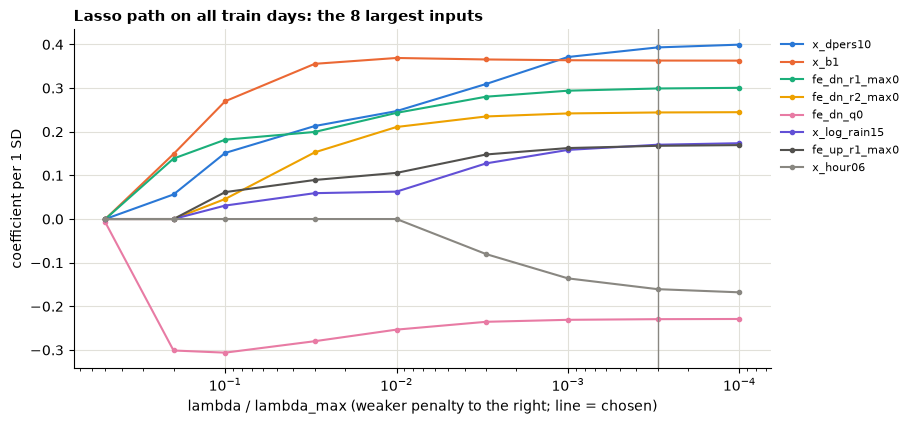

In [6]:
coef = fin[frac]["coef"]
order = np.argsort(-np.abs(coef))
seen = []
for f in S.LASSO_FRACS[:3]:                            # the order in which the inputs enter the path
    new = [xnames[i] for i in np.nonzero(fin[f]["coef"])[0] if xnames[i] not in seen]
    seen += new
    print(f"lambda_max x {f}: {fin[f]['nonzero']} inputs kept; entering here: {', '.join(new)}")
mdtable([[f"`{xnames[i]}`", f"{coef[i]:+.3f}"] for i in order[:15]], ["input (per 1 SD)", "coefficient"])
fig, ax = plt.subplots(figsize=(9, 4.4))
xs = np.array(S.LASSO_FRACS, float)
for j, i in enumerate(order[:8]):
    ax.plot(xs, [fin[f]["coef"][i] for f in S.LASSO_FRACS], marker="o", markersize=3, label=xnames[i],
            color=(SLOT + [INK2, MUTED])[j % 8])
ax.axvline(frac, color=MUTED, linewidth=1)
ax.set_xscale("log")
ax.invert_xaxis()
ax.set_xlabel("lambda / lambda_max (weaker penalty to the right; line = chosen)")
ax.set_ylabel("coefficient per 1 SD")
ax.set_title("Lasso path on all train days: the 8 largest inputs")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
save(fig, "part3_lasso_path.png")

With 4.6 M rows the penalty hardly changes the score once it is weak; its value is the order in which inputs enter
(printed above): band persistence and the queue inputs downstream come first. The largest weights go to band
persistence, the link's usual onset rate (HIST) and the drops within 1.5 km downstream; the same queue inputs 10
minutes earlier get negative weights, so a queue that has just appeared matters more than one that has been there.

## 5. M2: random forest

- Same 96 inputs, raw scale. Fit rows: every onset and 10% of the other rows (fixed seed), because the trees need
  balance more than volume; the probabilities are recalibrated on the validation week (section 6).
- **Tuning** on the same folds: max_features x min_samples_leaf, 150 trees each (ties at 4 decimals: the larger leaf,
  then the smaller max_features). The first grid's best sat on its edge, so it was widened once, on the folds only; this
  is the final grid. The final forest has 400 trees.

In [7]:
cols_rf = feature_list(fit_all.columns, chosen["RF"])
fold_mats = []
for k in range(len(S.FOLDS)):
    fit, chk = fold(k)
    fold_mats.append((tree_matrix(fit, cols_rf), fit["y"].to_numpy(), tree_matrix(chk, cols_rf), chk["y"].to_numpy()))
    del fit, chk
grid = {}
for g in S.RF_GRID:
    key = (g["max_features"], g["min_samples_leaf"])
    aps = []
    for k, (X1, y1, X2, y2) in enumerate(fold_mats):
        rf = fit_forest(X1, y1, S.RF_TREES_TUNE, S.SEED + k, **g)
        aps.append(ap(y2, forest_score(rf, X2)))
        del rf
    grid[key] = aps
    log(f"max_features {key[0]:.2f}, min_samples_leaf {key[1]:3d}: folds {aps[0]:.4f} {aps[1]:.4f}, mean {np.mean(aps):.4f}")
del fold_mats
gc.collect()
rule = max(grid, key=lambda k: (round(float(np.mean(grid[k])), 4), k[1], -k[0]))   # the written rule
fz = json.loads(S.FREEZE.read_text())
params = dict(fz["rf"]["params"])                     # the frozen choice (see the note below)
best = (params["max_features"], params["min_samples_leaf"])
leafs = sorted({k[1] for k in grid})
mdtable([[mf] + [f"**{np.mean(grid[(mf, lf)]):.4f}**" if (mf, lf) == best else f"{np.mean(grid[(mf, lf)]):.4f}" for lf in leafs]
         for mf in sorted({k[0] for k in grid})], ["max_features \\ min_samples_leaf"] + [str(lf) for lf in leafs])
print(f"fold means at full precision: max_features 0.35 -> {np.mean(grid[(0.35, 20)]):.6f}, "
      f"0.6 -> {np.mean(grid[(0.6, 20)]):.6f} (min_samples_leaf 20)")
print(f"the written rule picks max_features {rule[0]}, min_samples_leaf {rule[1]}; "
      f"the frozen run kept {params} (bold), which is used below")

[ 1273 s] max_features 0.15, min_samples_leaf   5: folds 0.3439 0.3909, mean 0.3674


[ 1330 s] max_features 0.15, min_samples_leaf  20: folds 0.3438 0.3924, mean 0.3681


[ 1383 s] max_features 0.15, min_samples_leaf  80: folds 0.3262 0.3811, mean 0.3537


[ 1429 s] max_features 0.15, min_samples_leaf 320: folds 0.3034 0.3615, mean 0.3325


[ 1546 s] max_features 0.35, min_samples_leaf   5: folds 0.3423 0.3892, mean 0.3658


[ 1653 s] max_features 0.35, min_samples_leaf  20: folds 0.3475 0.3948, mean 0.3712


... (4 outputs left out)

[ 2349 s] max_features 0.60, min_samples_leaf  80: folds 0.3382 0.3905, mean 0.3643


[ 2488 s] max_features 0.60, min_samples_leaf 320: folds 0.3142 0.3739, mean 0.3440


| max_features \ min_samples_leaf | 5 | 20 | 80 | 320 |
|---|---|---|---|---|
| 0.15 | 0.3674 | 0.3681 | 0.3537 | 0.3325 |
| 0.35 | 0.3658 | 0.3712 | 0.3630 | 0.3417 |
| 0.6 | 0.3624 | **0.3712** | 0.3643 | 0.3440 |

fold means at full precision: max_features 0.35 -> 0.371165, 0.6 -> 0.371236 (min_samples_leaf 20)
the written rule picks max_features 0.35, min_samples_leaf 20; the frozen run kept {'max_features': 0.6, 'min_samples_leaf': 20} (bold), which is used below


**A tie, and which setting the frozen run kept.** With min_samples_leaf 20, max_features 0.35 and 0.6 tie at 4
decimals: their fold means differ by less than 0.0001. The written rule sends ties to the smaller max_features, 0.35.
The frozen run kept 0.6. It ran the grid in two parts (the grid was widened once), and the first part's fold scores had
been stored rounded to 4 decimals. That put 0.35 at 0.3711 instead of 0.3712, so 0.6 came out ahead by a rounding
step. The choice used only the train days, and the test week was scored with 0.6, so the final forest here uses 0.6
too. To show that the tie does not matter, a forest with 0.35 is also fitted below and scored on the validation week;
it is not used anywhere else.

[ 2975 s] final forest: 400 trees, {'max_features': 0.6, 'min_samples_leaf': 20}


| forest (400 trees) | validation PR-AUC, training roads | AYE + CTE |
|---|---|---|
| max_features 0.6, min_samples_leaf 20 (frozen, used) | 0.3482 | 0.3352 |
| max_features 0.35, min_samples_leaf 20 (tie, not used) | 0.3496 | 0.3387 |

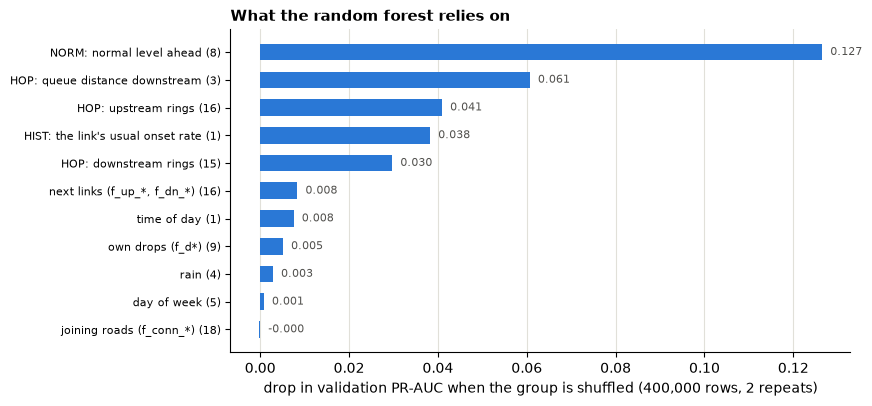

In [8]:
X = tree_matrix(fit_all, cols_rf)
m2 = fit_forest(X, yf, S.RF_TREES_FINAL, S.SEED, **params)
Xv = tree_matrix(val, cols_rf)
s_rf = forest_score(m2, Xv)
log(f"final forest: {S.RF_TREES_FINAL} trees, {params}")
alt = fit_forest(X, yf, S.RF_TREES_FINAL, S.SEED, max_features=0.35, min_samples_leaf=20)
s_alt = forest_score(alt, Xv)
del X, alt
vmain = ~val["heldout_road"].to_numpy()
yv_ = val["y"].to_numpy()
mdtable([[f"max_features {mf}, min_samples_leaf 20" + (" (frozen, used)" if mf == params["max_features"] else " (tie, not used)"),
          f"{ap(yv_[vmain], sc_[vmain]):.4f}", f"{ap(yv_[~vmain], sc_[~vmain]):.4f}"]
         for mf, sc_ in ((params["max_features"], s_rf), (0.35, s_alt))],
        ["forest (400 trees)", "validation PR-AUC, training roads", "AYE + CTE"])
del s_alt

def grp(c):
    if c.startswith("f_conn_"): return "joining roads (f_conn_*)"
    if c.startswith(("f_up_", "f_dn_")): return "next links (f_up_*, f_dn_*)"
    if c.startswith("fe_dn_q"): return "HOP: queue distance downstream"
    if c.startswith("fe_dn_"): return "HOP: downstream rings"
    if c.startswith("fe_up_"): return "HOP: upstream rings"
    if c.startswith(("f_d", "f_n_filled")): return "own drops (f_d*)"
    if c.startswith("f_rain"): return "rain"
    if c == "f_slot15": return "time of day"
    if c in ("f_mon", "f_tue", "f_wed", "f_thu", "f_fri"): return "day of week"
    if c == "x_b1": return "HIST: the link's usual onset rate"
    return "NORM: normal level ahead"
main_i = np.nonzero(~val["heldout_road"].to_numpy())[0]
idx = np.sort(np.random.default_rng(S.SEED).choice(main_i, 400_000, replace=False))
Xs, ys = Xv[idx], val["y"].to_numpy()[idx]
base_ap = ap(ys, forest_score(m2, Xs))
gmap = {}
for i, c in enumerate(cols_rf):
    gmap.setdefault(grp(c), []).append(i)
imp = []
for g, ii in gmap.items():
    drops = []
    for r in range(2):
        Xp = Xs.copy()
        perm = np.random.default_rng(S.SEED + r).permutation(len(Xp))
        Xp[:, ii] = Xs[perm][:, ii]                 # shuffle the whole group together
        drops.append(base_ap - ap(ys, forest_score(m2, Xp)))
    imp.append((g, len(ii), float(np.mean(drops))))
imp.sort(key=lambda r: -r[2])
del Xv, Xs, Xp
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(range(len(imp))[::-1], [d_ for _, _, d_ in imp], color=SLOT[0], height=0.6)
ax.set_yticks(range(len(imp))[::-1])
ax.set_yticklabels([f"{g} ({n})" for g, n, _ in imp], fontsize=8)
for i, (_, _, d_) in zip(range(len(imp))[::-1], imp):
    ax.text(max(d_, 0), i, f"  {d_:.3f}", va="center", fontsize=8, color=INK2)
ax.set_xlabel("drop in validation PR-AUC when the group is shuffled (400,000 rows, 2 repeats)")
ax.set_title("What the random forest relies on")
ax.grid(axis="y", visible=False)
save(fig, "part3_forest_importance.png")

The forest relies most on the normal level ahead, then on the queue inputs (HOP) and each link's usual onset rate. The
joining roads add nothing. Grouped permutation importance shows reliance, not cause: correlated groups share credit.

## 6. The validation week (Tue 10 - Fri 13 Nov)

Everything is chosen here, then frozen: the final model (higher PR-AUC of M1 and M2 on the training roads), the
calibration (a Platt map on the logit scale), and the alert share (best F1 of the final model). **Band persistence** is
shown as a reference: the drop the link would have at t + 10 and t + 15 if its band stayed the same (no fitting).

In [9]:
v = (val.select("LinkID", "t", "date", "heldout_road", "y", "f_d0", "x_lowpers15", "fe_dn_q0",
                pl.min_horizontal("x_dpers10", "x_dpers15").cast(pl.Float64).alias("b2p"))
        .with_columns(pl.Series("lasso", s_lasso), pl.Series("rf_raw", s_rf))
        .join(vb, on=["LinkID", "t"], how="left", maintain_order="left"))
assert v["b1"].null_count() == 0
MODELS = {"B1": "b1", "B2": "b2", "B2p": "b2p", "Lasso": "lasso", "RF": "rf_raw"}
LABEL = {"B1": "B1 time-of-week rate", "B2": "B2 last observation", "B2p": "band persistence (reference)",
         "Lasso": "M1 lasso", "RF": "M2 random forest"}
COLOR = {"B1": MUTED, "B2": INK2, "B2p": SLOT[2], "Lasso": SLOT[1], "RF": SLOT[0]}
vdays = sorted(v["date"].unique().to_list())
v = v.with_columns(pl.col("date").replace_strict({d: i for i, d in enumerate(vdays)}).alias("di"))
main = v.filter(~pl.col("heldout_road"))
trans = v.filter(pl.col("heldout_road"))
res_rows, pr_main = [], {}
for name, col in MODELS.items():
    for lab, d_ in (("training roads", main), ("AYE + CTE", trans)):
        y, s, t = d_["y"].to_numpy(), d_[col].to_numpy(), d_["t"].to_numpy()
        pr = [prec_rec_at_share(t, y, s, q) for q in S.SHARE_GRID]
        if lab == "training roads":
            pr_main[name] = pr
        res_rows.append([LABEL[name], lab, f"{ap(y, s):.4f}"] + [f"{p:.3f} / {r:.3f}" for p, r, _ in
                                                                [pr[S.SHARE_GRID.index(q)] for q in S.SHARES]])
mdtable(res_rows, ["score", "roads", "PR-AUC", "precision / recall, top 0.5%", "top 1%", "top 2%"])
ap_main = {n: ap(main["y"].to_numpy(), main[c].to_numpy()) for n, c in MODELS.items()}
final = max(("Lasso", "RF"), key=lambda n: ap_main[n])
f1 = {q: (2 * p * r / (p + r) if p + r else 0.0) for q, (p, r, _) in zip(S.SHARE_GRID, pr_main[final])}
share = min(S.SHARE_GRID, key=lambda q: (-round(f1[q], 4), q))
mdtable([[f"{100 * q:g}%", f"{p:.3f}", f"{r:.3f}", f"**{f1[q]:.3f}**" if q == share else f"{f1[q]:.3f}",
          f"{n_a / (len(vdays) * 192):.1f}"] for q, (p, r, n_a) in zip(S.SHARE_GRID, pr_main[final])],
        ["alert share", "precision", "recall", "F1", "alerts per update (1,909 links)"])
print(f"final model: {LABEL[final]}; operating share {100 * share:g}% (best F1)")

| score | roads | PR-AUC | precision / recall, top 0.5% | top 1% | top 2% |
|---|---|---|---|---|---|
| B1 time-of-week rate | training roads | 0.0688 | 0.106 / 0.048 | 0.092 / 0.080 | 0.079 / 0.137 |
| B1 time-of-week rate | AYE + CTE | 0.0232 | 0.019 / 0.008 | 0.018 / 0.013 | 0.017 / 0.023 |
| B2 last observation | training roads | 0.1284 | 0.256 / 0.116 | 0.194 / 0.170 | 0.138 / 0.237 |
| B2 last observation | AYE + CTE | 0.1431 | 0.230 / 0.094 | 0.197 / 0.140 | 0.148 / 0.205 |
| band persistence (reference) | training roads | 0.1710 | 0.297 / 0.135 | 0.233 / 0.204 | 0.166 / 0.287 |
| band persistence (reference) | AYE + CTE | 0.1710 | 0.274 / 0.112 | 0.231 / 0.164 | 0.176 / 0.245 |
| M1 lasso | training roads | 0.3220 | 0.353 / 0.160 | 0.289 / 0.253 | 0.220 / 0.379 |
| M1 lasso | AYE + CTE | 0.3004 | 0.278 / 0.113 | 0.254 / 0.180 | 0.206 / 0.286 |
| M2 random forest | training roads | 0.3482 | 0.370 / 0.168 | 0.299 / 0.262 | 0.225 / 0.389 |
| M2 random forest | AYE + CTE | 0.3352 | 0.312 / 0.127 | 0.279 / 0.198 | 0.225 / 0.313 |

| alert share | precision | recall | F1 | alerts per update (1,909 links) |
|---|---|---|---|---|
| 0.25% | 0.435 | 0.104 | 0.168 | 4.3 |
| 0.5% | 0.370 | 0.168 | 0.231 | 8.2 |
| 1% | 0.299 | 0.262 | 0.280 | 15.8 |
| 2% | 0.225 | 0.389 | **0.285** | 31.2 |
| 3% | 0.184 | 0.475 | 0.266 | 46.5 |
| 5% | 0.136 | 0.580 | 0.220 | 77.2 |

final model: M2 random forest; operating share 2% (best F1)


| model | mean raw chance | mean calibrated (cross-fitted) | observed | Brier (cross-fitted) | Brier of the onset rate | map: logit p' = a + b logit p |
|---|---|---|---|---|---|---|
| B1 time-of-week rate | 0.0096 | 0.0119 | 0.0118 | 0.01133 | 0.01164 | a = -0.164, b = 0.909 |
| M1 lasso | 0.0118 | 0.0118 | 0.0118 | 0.00947 | 0.01164 | a = -0.098, b = 0.967 |
| M2 random forest | 0.0600 | 0.0117 | 0.0118 | 0.00924 | 0.01164 | a = -2.297, b = 0.996 |

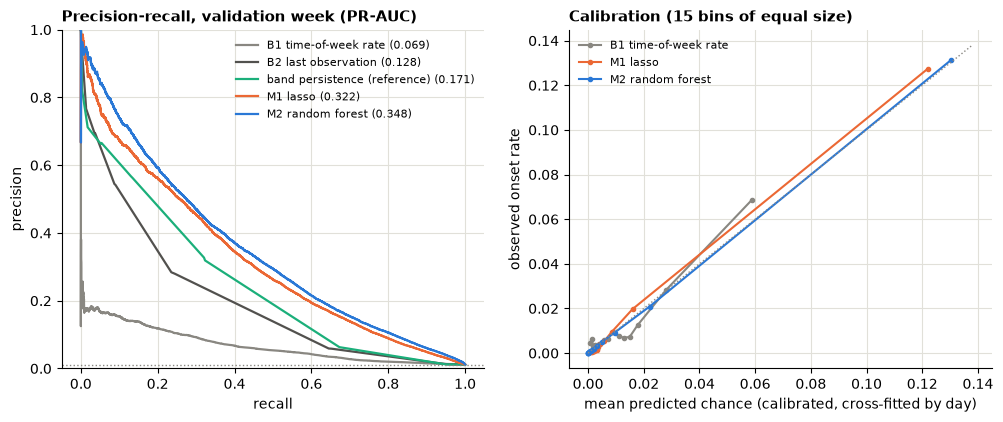

In [10]:
def logit(p):
    p = np.clip(np.asarray(p, float), 1e-7, 1 - 1e-7)
    return np.log(p / (1 - p))
def platt_fit(p, y):
    m = LogisticRegression(C=np.inf, solver="lbfgs").fit(logit(p).reshape(-1, 1), y)
    return float(m.intercept_[0]), float(m.coef_[0, 0])
def platt_apply(p, ab):
    return 1 / (1 + np.exp(-(ab[0] + ab[1] * logit(p))))

calib, cal_rows, cross = {}, [], {}
y, di = main["y"].to_numpy(), main["di"].to_numpy()
for name in ("B1", "Lasso", "RF"):
    p = main[MODELS[name]].to_numpy()
    calib[name] = platt_fit(p, y)
    cr = np.empty_like(p, dtype=float)
    for d_ in range(len(vdays)):                   # honest check: fit the map on 3 days, apply it to the 4th
        k_ = di == d_
        cr[k_] = platt_apply(p[k_], platt_fit(p[~k_], y[~k_]))
    cross[name] = cr
    cal_rows.append([LABEL[name], f"{p.mean():.4f}", f"{cr.mean():.4f}", f"{y.mean():.4f}", f"{brier(y, cr):.5f}",
                     f"{brier(y, np.full_like(p, y.mean())):.5f}", f"a = {calib[name][0]:+.3f}, b = {calib[name][1]:.3f}"])
mdtable(cal_rows, ["model", "mean raw chance", "mean calibrated (cross-fitted)", "observed", "Brier (cross-fitted)",
                   "Brier of the onset rate", "map: logit p' = a + b logit p"])
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
for n in ("B1", "B2", "B2p", "Lasso", "RF"):
    pr_, rc_, _ = precision_recall_curve(y, main[MODELS[n]].to_numpy())
    axs[0].plot(rc_, pr_, color=COLOR[n], linewidth=1.6, label=f"{LABEL[n]} ({ap_main[n]:.3f})")
axs[0].axhline(y.mean(), color=MUTED, linestyle=":", linewidth=1)
axs[0].set_xlabel("recall")
axs[0].set_ylabel("precision")
axs[0].set_ylim(0, 1)
axs[0].set_title("Precision-recall, validation week (PR-AUC)")
axs[0].legend(fontsize=8)
for n in ("B1", "Lasso", "RF"):
    rel = reliability(y, cross[n], bins=15)
    axs[1].plot(rel["mean_pred"], rel["observed"], marker="o", markersize=3, color=COLOR[n], label=LABEL[n])
lim = max(axs[1].get_xlim()[1], axs[1].get_ylim()[1])
axs[1].plot([0, lim], [0, lim], color=MUTED, linewidth=1, linestyle=":")
axs[1].set_xlabel("mean predicted chance (calibrated, cross-fitted by day)")
axs[1].set_ylabel("observed onset rate")
axs[1].set_title("Calibration (15 bins of equal size)")
axs[1].legend(fontsize=8)
save(fig, "part3_validation_pr_calibration.png")

In [11]:
per_day = [[f"{d_:%a %d %b}", f"{main.filter(pl.col('di') == i)['y'].mean():.4f}"]
           + [f"{ap(main.filter(pl.col('di') == i)['y'].to_numpy(), main.filter(pl.col('di') == i)[c].to_numpy()):.4f}"
              for c in MODELS.values()] for i, d_ in enumerate(vdays)]
mdtable(per_day, ["day", "onset rate"] + [LABEL[n] for n in MODELS])

full_u = (pl.scan_parquet(S.FULL).filter(pl.col("in_population") & (pl.col("split") == "validate"))
            .select("LinkID", "t", "U", "heldout_road").collect())
prev = full_u.select("LinkID", (pl.col("t") + timedelta(minutes=5)).alias("t"), pl.col("U").alias("U_prev"))
episodes = (full_u.join(prev, on=["LinkID", "t"], how="left").filter(pl.col("U") & (pl.col("U_prev") == False))
                  .filter(~pl.col("heldout_road")).select("LinkID", pl.col("t").alias("s")))
def event_level(d_, col, q):
    a = alerts_at_share(d_["t"].to_numpy(), d_[col].to_numpy(), q)
    al = d_.filter(pl.Series(a)).select("LinkID", "t", "y")
    hit = pl.concat([al.select("LinkID", (pl.col("t") + timedelta(minutes=k_)).alias("s")) for k_ in (10, 15)]).unique()
    return (episodes.join(hit, on=["LinkID", "s"], how="semi").height / episodes.height,
            al.filter(~pl.col("y")).height / (len(vdays) * 16))
bs = DayBootstrap(main["di"].to_numpy(), len(vdays))
boots = {n: bs.replicate_aps(main[c].to_numpy(), y) for n, c in MODELS.items()}
ev = {n: event_level(main, c, share) for n, c in MODELS.items()}
mdtable([[LABEL[n], f"{ap_main[n]:.4f}", "{:.3f} to {:.3f}".format(*ci(boots[n])),
          "" if n in ("B1", "B2") else "{:+.3f} ({:+.3f} to {:+.3f})".format(ap_main[n] - ap_main["B2"], *ci(boots[n] - boots["B2"])),
          f"{ev[n][0]:.1%}", f"{ev[n][1]:,.0f}"] for n in MODELS],
        ["score", "PR-AUC", "day-block 95% interval (4 days)", "minus B2 (paired)",
         f"episodes warned 10-15 min ahead ({100 * share:g}%)", "false alarms per hour"])
print(f"{episodes.height:,} episodes start in the validation week on the training roads")
del full_u, prev

| day | onset rate | B1 time-of-week rate | B2 last observation | band persistence (reference) | M1 lasso | M2 random forest |
|---|---|---|---|---|---|---|
| Tue 10 Nov | 0.0128 | 0.0953 | 0.1630 | 0.2078 | 0.3890 | 0.4245 |
| Wed 11 Nov | 0.0087 | 0.0957 | 0.1352 | 0.2113 | 0.3638 | 0.3941 |
| Thu 12 Nov | 0.0150 | 0.0437 | 0.0742 | 0.0897 | 0.1668 | 0.1796 |
| Fri 13 Nov | 0.0115 | 0.0551 | 0.1624 | 0.2047 | 0.3684 | 0.3946 |

| score | PR-AUC | day-block 95% interval (4 days) | minus B2 (paired) | episodes warned 10-15 min ahead (2%) | false alarms per hour |
|---|---|---|---|---|---|
| B1 time-of-week rate | 0.0688 | 0.049 to 0.094 |  | 13.9% | 344 |
| B2 last observation | 0.1284 | 0.091 to 0.163 |  | 8.4% | 323 |
| band persistence (reference) | 0.1710 | 0.112 to 0.208 | +0.043 (+0.024 to +0.066) | 15.7% | 312 |
| M1 lasso | 0.3220 | 0.216 to 0.384 | +0.194 (+0.125 to +0.229) | 31.0% | 292 |
| M2 random forest | 0.3482 | 0.233 to 0.418 | +0.220 (+0.141 to +0.261) | 30.3% | 290 |

7,481 episodes start in the validation week on the training roads


Both models beat both baselines on every validation day, by a wide margin. Thu 12 Nov is the weakest day for every
score (the second collector was down). With 4 days, the interval only shows that the code works; the test week's 5
days give the real one (section 11). The final model is the random forest, its probabilities need the calibration map
(they are about 5 times too high because of the 10% subsample), and the alert share is 2% (about 31 alerts per
update over 1,909 links).

## 7. ROC curve, AUC and the confusion matrix

The course's standard tools for a yes / no model, on the validation week (training roads). An alert is a "predict 1":
we alert on the top 2% of links at each update. *Sensitivity* = share of onsets alerted (recall); *specificity* = share
of non-onsets not alerted; *accuracy* = share of rows classified correctly.

| score | PR-AUC | ROC-AUC (lowest-highest day) | TP | FP | FN | TN | sensitivity | specificity | precision | accuracy |
|---|---|---|---|---|---|---|---|---|---|---|
| B1 time-of-week rate | 0.069 | 0.770 (0.679-0.864) | 1,902 | 22,042 | 11,981 | 1,142,541 | 0.137 | 0.9811 | 0.079 | 0.9711 |
| B2 last observation | 0.128 | 0.771 (0.725-0.798) | 3,295 | 20,649 | 10,588 | 1,143,934 | 0.237 | 0.9823 | 0.138 | 0.9735 |
| band persistence (reference) | 0.171 | 0.786 (0.746-0.804) | 3,981 | 19,963 | 9,902 | 1,144,620 | 0.287 | 0.9829 | 0.166 | 0.9747 |
| M1 lasso | 0.322 | 0.927 (0.861-0.950) | 5,266 | 18,678 | 8,617 | 1,145,905 | 0.379 | 0.9840 | 0.220 | 0.9768 |
| M2 random forest | 0.348 | 0.942 (0.884-0.959) | 5,397 | 18,547 | 8,486 | 1,146,036 | 0.389 | 0.9841 | 0.225 | 0.9771 |

a rule that never alerts has accuracy 0.9882


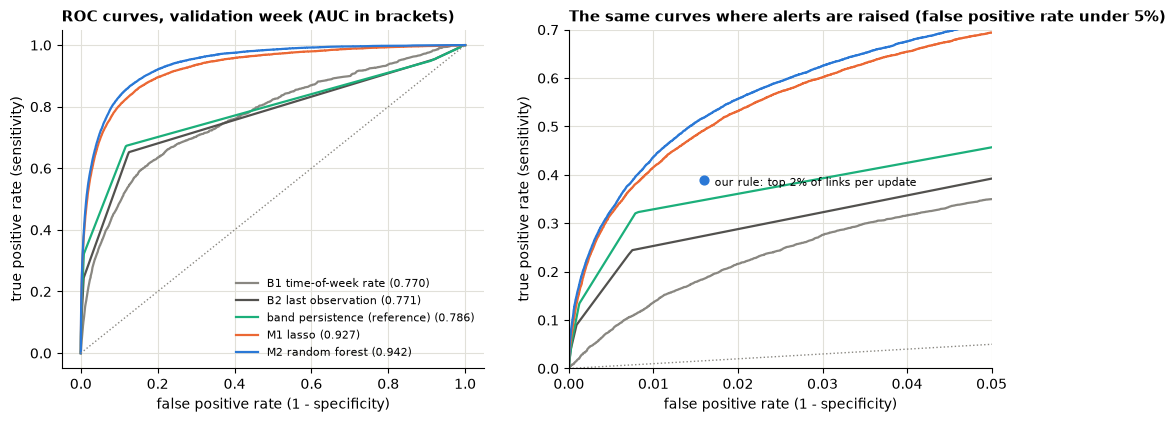

In [12]:
y = main["y"].to_numpy()
tvec = main["t"].to_numpy()
N, P = len(y), int(y.sum())
roc_rows, perf = [], {}
for n, c in MODELS.items():
    s = main[c].to_numpy().astype(float)
    a = alerts_at_share(tvec, s, share)
    tp, fp = int((a & y).sum()), int((a & ~y).sum())
    fn, tn = P - tp, N - P - fp
    days_auc = [float(roc_auc_score(y[main["di"].to_numpy() == d_], s[main["di"].to_numpy() == d_])) for d_ in range(len(vdays))]
    perf[n] = {"roc_auc": float(roc_auc_score(y, s)), "tp": tp, "fp": fp, "fn": fn, "tn": tn}
    roc_rows.append([LABEL[n], f"{ap_main[n]:.3f}", f"{perf[n]['roc_auc']:.3f} ({min(days_auc):.3f}-{max(days_auc):.3f})",
                     f"{tp:,}", f"{fp:,}", f"{fn:,}", f"{tn:,}", f"{tp / P:.3f}", f"{tn / (N - P):.4f}",
                     f"{tp / max(1, tp + fp):.3f}", f"{(tp + tn) / N:.4f}"])
mdtable(roc_rows, ["score", "PR-AUC", "ROC-AUC (lowest-highest day)", "TP", "FP", "FN", "TN", "sensitivity",
                   "specificity", "precision", "accuracy"])
print(f"a rule that never alerts has accuracy {1 - P / N:.4f}")
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
for n, c in MODELS.items():
    fpr, tpr, _ = roc_curve(y, main[c].to_numpy().astype(float))
    for ax in axs:
        ax.plot(fpr, tpr, color=COLOR[n], linewidth=1.6, label=f"{LABEL[n]} ({perf[n]['roc_auc']:.3f})")
for ax in axs:
    ax.plot([0, 1], [0, 1], color=MUTED, linestyle=":", linewidth=1)
    ax.set_xlabel("false positive rate (1 - specificity)")
    ax.set_ylabel("true positive rate (sensitivity)")
axs[0].set_title("ROC curves, validation week (AUC in brackets)")
axs[0].legend(fontsize=8, loc="lower right")
rf_ = perf[final]
axs[1].set_xlim(0, 0.05)
axs[1].set_ylim(0, 0.7)
axs[1].scatter([rf_["fp"] / (N - P)], [rf_["tp"] / P], color=COLOR[final], s=40, zorder=3)
axs[1].annotate("our rule: top 2% of links per update", (rf_["fp"] / (N - P), rf_["tp"] / P), textcoords="offset points",
                xytext=(8, -4), fontsize=8)
axs[1].set_title("The same curves where alerts are raised (false positive rate under 5%)")
save(fig, "part3_roc.png")

- **ROC-AUC ranks the models as PR-AUC does**, but it hides what matters here. With about 1% onsets, most of the ROC
  curve lies where nobody would operate: a false positive rate of 5% already means about 75 false alarms at every
  update. The two baselines look alike on ROC-AUC, though last observation's alerts are almost twice as precise.
  PR-AUC is therefore the main score, with ROC-AUC next to it.
- **Accuracy cannot be the criterion**: every score is less accurate than never alerting.
- The operating point lies below the forest's ROC curve because the rule takes the top 2% of links at *every* update,
  not one probability threshold for the whole week.

## 8. Check against the frozen run

The settings chosen above were frozen on 25 Nov (`results/freeze.json`, with file hashes) before the test week was opened,
and the frozen models were scored once on the test week. This check confirms that this notebook rebuilds **the same
models**: the same choices, and the same validation scores row by row. The one difference is the forest's tie
explained in section 5, where the frozen choice is used.

In [13]:
fz = json.loads(S.FREEZE.read_text())
same = [["B1: m", m_b1, fz["B1"]["m"]],
        ["inputs, lasso", " + ".join(chosen["LR"]), " + ".join(fz["features"]["LR"])],
        ["inputs, forest", " + ".join(chosen["RF"]), " + ".join(fz["features"]["RF"])],
        ["lasso penalty (x lambda_max)", frac, fz["lasso"]["frac_of_lambda_max"]],
        ["forest settings by the written rule, at full precision", {"max_features": rule[0], "min_samples_leaf": rule[1]},
         fz["rf"]["params"]],
        ["forest settings used", params, fz["rf"]["params"]],
        ["final model", final, fz["final_model"]],
        ["alert share", share, fz["operating_share"]]]
for n in ("B1", "Lasso", "RF"):
    same.append([f"calibration map, {n}", tuple(round(x, 6) for x in calib[n]),
                 tuple(round(x, 6) for x in fz["calibration_platt_logit"][n])])
frozen = (pl.read_parquet(S.PREDS / "val_baselines.parquet").select("LinkID", "t", "b1", "b2")
            .join(pl.read_parquet(S.PREDS / "val_lasso.parquet").select("LinkID", "t", "lasso"), on=["LinkID", "t"])
            .join(pl.read_parquet(S.PREDS / "val_rf.parquet").select("LinkID", "t", "rf_raw"), on=["LinkID", "t"]))
cmp = v.select("LinkID", "t", "b1", "b2", "lasso", "rf_raw").join(frozen, on=["LinkID", "t"], how="full", suffix="_frozen")
assert cmp.height == v.height == frozen.height and cmp["b1"].null_count() == 0 and cmp["b1_frozen"].null_count() == 0
for c in ("b1", "b2", "lasso", "rf_raw"):
    diff = float((cmp[c] - cmp[f"{c}_frozen"]).abs().max())
    same.append([f"validation scores, {c} (largest difference over {v.height:,} rows)", f"{diff:.1e}", "0"])
def agree(a, b, c):
    return str(b) == str(c) or (a.startswith("validation") and float(b) < 1e-9)
mdtable([[a, b, c, "yes" if agree(a, b, c) else ("no: a tie at 4 decimals (section 5)" if "written rule" in a else "NO")]
         for a, b, c in same], ["item", "this notebook", "frozen run", "same"])
assert all(agree(a, b, c) or "written rule" in a for a, b, c in same)

| item | this notebook | frozen run | same |
|---|---|---|---|
| B1: m | 48 | 48 | yes |
| inputs, lasso | BASE + NORM + HOP + HIST | BASE + NORM + HOP + HIST | yes |
| inputs, forest | BASE + NORM + HOP + HIST | BASE + NORM + HOP + HIST | yes |
| lasso penalty (x lambda_max) | 0.0003 | 0.0003 | yes |
| forest settings by the written rule, at full precision | {'max_features': 0.35, 'min_samples_leaf': 20} | {'max_features': 0.6, 'min_samples_leaf': 20} | no: a tie at 4 decimals (section 5) |
| forest settings used | {'max_features': 0.6, 'min_samples_leaf': 20} | {'max_features': 0.6, 'min_samples_leaf': 20} | yes |
| final model | RF | RF | yes |
| alert share | 0.02 | 0.02 | yes |
| calibration map, B1 | (-0.163586, 0.909236) | (-0.163586, 0.909236) | yes |
| calibration map, Lasso | (-0.098152, 0.967044) | (-0.098152, 0.967044) | yes |
| calibration map, RF | (-2.296988, 0.996338) | (-2.296988, 0.996338) | yes |
| validation scores, b1 (largest difference over 1,607,133 rows) | 0.0e+00 | 0 | yes |
| validation scores, b2 (largest difference over 1,607,133 rows) | 0.0e+00 | 0 | yes |
| validation scores, lasso (largest difference over 1,607,133 rows) | 0.0e+00 | 0 | yes |
| validation scores, rf_raw (largest difference over 1,607,133 rows) | 4.4e-16 | 0 | yes |

## 9. Where the models work, and where they cannot: results by kind of onset

The rows that are normal now are split into three groups **using only what is known at time t** (rules fixed before any
model was scored by group; Part 2, section 8):

- **A, forming here**: the link is already below its normal level, or band persistence says it will be unusual at t + 15;
- **B, queue ahead**: not A, and a link up to 500 m downstream is low now;
- **C, new**: neither.

Because the groups use no future information, every row falls in exactly one group whatever happens later, and the
alerts are the same as in section 6 (the top 2% of links at each update, chosen over all rows). Validation week,
training roads.

In [14]:
grp_expr = (pl.when((pl.col("f_d0") > 0) | (pl.col("x_lowpers15") == 1)).then(pl.lit("A forming here"))
              .when(pl.col("fe_dn_q0") <= 500).then(pl.lit("B queue ahead")).otherwise(pl.lit("C new")))
main = main.with_columns(grp_expr.alias("group"))
alerts = {n: alerts_at_share(main["t"].to_numpy(), main[c].to_numpy(), share) for n, c in MODELS.items()}
y = main["y"].to_numpy()
by_group = []
for g in ("A forming here", "B queue ahead", "C new"):
    k_ = (main["group"] == g).to_numpy()
    for n in ("B1", "B2", "Lasso", "RF"):
        a = alerts[n]
        by_group.append([g if n == "B1" else "", f"{k_.mean():.1%}" if n == "B1" else "",
                         f"{y[k_].sum() / y.sum():.1%}" if n == "B1" else "", f"{y[k_].mean():.4f}" if n == "B1" else "",
                         LABEL[n], f"{ap(y[k_], main[MODELS[n]].to_numpy()[k_]):.3f}",
                         f"{(a & y & k_).sum() / max(1, (y & k_).sum()):.1%}", f"{(a & y & k_).sum() / max(1, (a & k_).sum()):.3f}"])
mdtable(by_group, ["group", "share of rows", "share of onsets", "onset rate", "score", "PR-AUC in the group",
                   f"recall at {100 * share:g}%", "precision"])

| group | share of rows | share of onsets | onset rate | score | PR-AUC in the group | recall at 2% | precision |
|---|---|---|---|---|---|---|---|
| A forming here | 13.2% | 67.5% | 0.0601 | B1 time-of-week rate | 0.200 | 15.1% | 0.260 |
|  |  |  |  | B2 last observation | 0.186 | 35.2% | 0.138 |
|  |  |  |  | M1 lasso | 0.415 | 49.6% | 0.285 |
|  |  |  |  | M2 random forest | 0.446 | 51.2% | 0.278 |
| B queue ahead | 2.1% | 10.7% | 0.0594 | B1 time-of-week rate | 0.119 | 8.2% | 0.131 |
|  |  |  |  | B2 last observation | 0.061 | 0.0% | 0.000 |
|  |  |  |  | M1 lasso | 0.227 | 33.3% | 0.127 |
|  |  |  |  | M2 random forest | 0.240 | 34.8% | 0.157 |
| C new | 84.7% | 21.8% | 0.0030 | B1 time-of-week rate | 0.018 | 12.1% | 0.021 |
|  |  |  |  | B2 last observation | 0.003 | 0.0% | 0.000 |
|  |  |  |  | M1 lasso | 0.044 | 4.3% | 0.034 |
|  |  |  |  | M2 random forest | 0.053 | 2.7% | 0.024 |

The models are strong when the slowdown is **already forming** on the link (group A) or a **queue is just ahead**
(group B). There they rank onsets far better than both baselines (forest PR-AUC 0.45 and 0.24, against at most 0.20 and
0.12) and catch about half and a third of them. Last observation (B2) catches none in group B, because there the link
itself still looks normal.

**New slowdowns** (group C: 85% of the rows and 22% of the onsets, an onset rate of only 0.3%) are hard for every score:
the best PR-AUC in the group is about 0.05, and the models catch only 3-4% of them at the 2% alert share. The
time-of-week rate catches more of these (12%), because it spreads its alerts over links that are often slow at that
time, whatever their state now; overall it catches far fewer onsets (14% against 39% for the forest). The data
(10 km/h bands every 5 minutes, no traffic volumes) carry almost no warning of a slowdown that has not started
anywhere nearby.

So the honest reading of the results: the models predict **where an existing slowdown will spread or deepen** in the
next 15 minutes; they cannot foresee slowdowns that start from nothing.

## 10. Other course tools (supporting checks)

These checks use tools from the course beyond the two models of the proposal. They are run by the scripts
`modelling/14_validation_windows.py`, `15_tree_and_importance.py` and `16_classifiers_and_roc.py`, on the train days
and the validation week only; their saved results are shown here.

1. Validation by windows: the two frozen windows (W2) and six windows that add 2 days at a time (W6)


| setting | W2: mean of the windows | W6: mean of the windows | W6: pooled |
|---|---|---|---|
| lasso, lambda / lambda_max = 0.01 | 0.3434 | 0.3377 | 0.3431 |
| lasso, lambda / lambda_max = 0.001 | 0.3527 | 0.3444 | 0.3500 |
| lasso, lambda / lambda_max = 0.0003 | 0.3530 | 0.3438 | 0.3495 |
| forest, max_features 0.35, leaf 20 | 0.3712 | 0.3690 | 0.3758 |
| forest, max_features 0.6, leaf 20 (frozen) | 0.3712 | 0.3683 | 0.3754 |
| forest, sqrt(p) inputs, leaf 20 | 0.3623 | 0.3624 | 0.3687 |
| forest, all inputs (bagging), leaf 20 | 0.3666 | 0.3607 | 0.3691 |

2. One decision tree, pruned by cost-complexity (size chosen on the six windows)


| tree | leaves | PR-AUC on its own fit rows | mean of the six windows | validation week |
|---|---|---|---|---|
| minimum-error rule | 83 | 0.730 | 0.287 | 0.268 |
| one-standard-error rule | 47 | 0.716 | 0.280 | 0.258 |
| unpruned | 6,216 | 0.858 | 0.239 | - |
| random forest (frozen) | 400 trees | - | - | 0.348 |

3. The forest's inputs ranked: permutation importance (drop in validation PR-AUC) and impurity importance


| rank | input | permutation | impurity |
|---|---|---|---|
| 1 | `x_dpers10` | 0.0692 | 0.1930 |
| 2 | `fe_dn_q0` | 0.0461 | 0.3528 |
| 3 | `x_b1` | 0.0363 | 0.0546 |
| 4 | `x_lowpers15` | 0.0281 | 0.0788 |
| 5 | `fe_up_q0` | 0.0224 | 0.0328 |
| 6 | `f_slot15` | 0.0083 | 0.0191 |
| 7 | `fe_dn_qmove` | 0.0081 | 0.0154 |
| 8 | `x_dpers15` | 0.0077 | 0.0340 |

... (2 outputs left out)

5. Other penalties and classifiers (mean PR-AUC of the six windows)


| model | mean of the six windows |
|---|---|
| ridge, weak penalty | 0.3439 |
| elastic net, weak penalty | 0.3438 |
| linear discriminant analysis | 0.2760 |
| quadratic discriminant analysis | 0.0782 |
| lasso (frozen penalty) | 0.3438 |

6. Thresholds from unequal costs: alert when the calibrated probability exceeds 1 / (1 + r)


| r = cost of a miss in false alarms | threshold | alerts per update | sensitivity | precision | cost per 1,000 rows | top-2% rule | never alert |
|---|---|---|---|---|---|---|---|
| 1 | 0.500 | 3.3 | 0.126 | 0.697 | 10.9 | 22.9 | 11.8 |
| 5 | 0.167 | 22.9 | 0.433 | 0.341 | 43.2 | 51.7 | 58.9 |
| 10 | 0.091 | 44.0 | 0.573 | 0.236 | 72.2 | 87.7 | 117.8 |
| 20 | 0.048 | 81.1 | 0.697 | 0.155 | 116.1 | 159.8 | 235.6 |
| 50 | 0.020 | 159.5 | 0.826 | 0.094 | 196.9 | 375.8 | 589.0 |

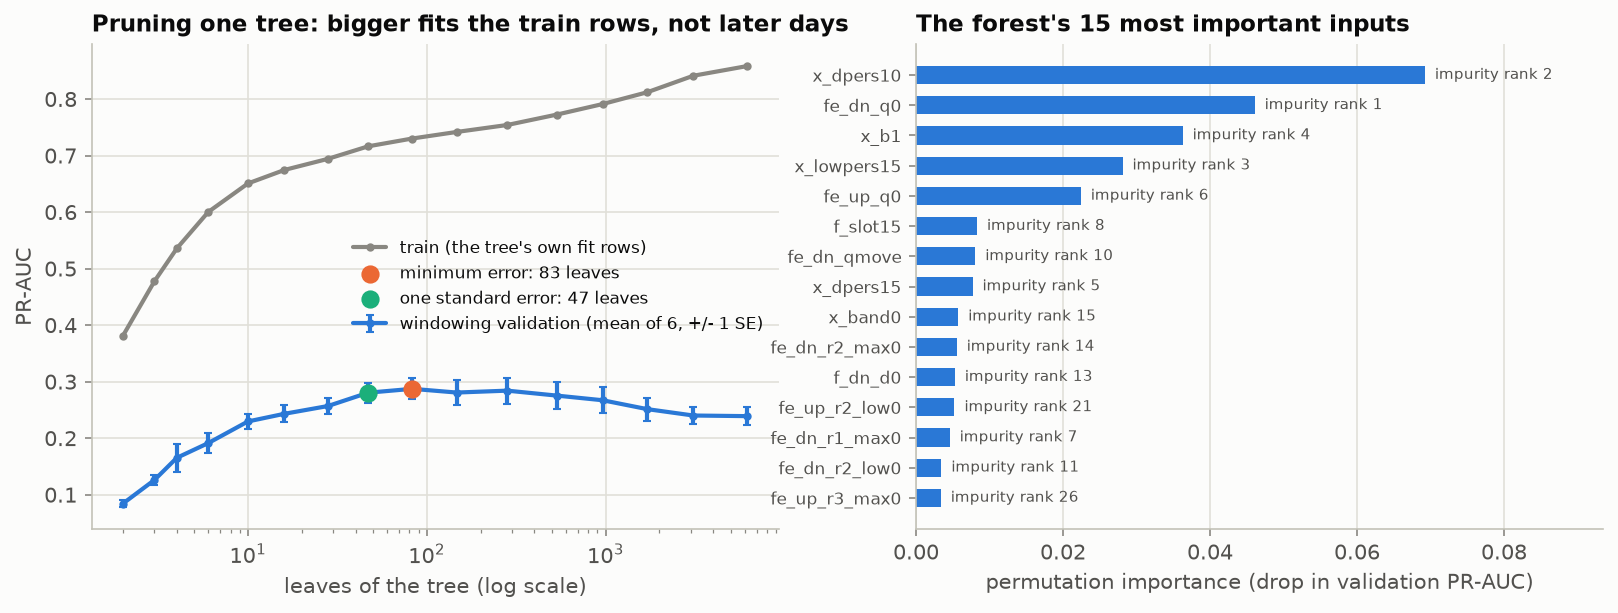

In [15]:
W = json.loads((S.TABLES / "14_validation_windows.json").read_text())
TR = json.loads((S.TABLES / "15_tree_and_importance.json").read_text())
CL = json.loads((S.TABLES / "16_classifiers_and_roc.json").read_text())

print("1. Validation by windows: the two frozen windows (W2) and six windows that add 2 days at a time (W6)")
mdtable([[f"lasso, lambda / lambda_max = {f}", f"{W['lasso']['W2'][f]['mean']:.4f}", f"{W['lasso']['W6'][f]['mean']:.4f}",
          f"{W['lasso']['W6'][f]['pooled']:.4f}"] for f in ("0.01", "0.001", "0.0003")]
        + [[lab, f"{W['forest']['W2'][k]['mean']:.4f}", f"{W['forest']['W6'][k]['mean']:.4f}", f"{W['forest']['W6'][k]['pooled']:.4f}"]
           for k, lab in (("0.35|20", "forest, max_features 0.35, leaf 20"), ("0.6|20", "forest, max_features 0.6, leaf 20 (frozen)"),
                          ("sqrt|20", "forest, sqrt(p) inputs, leaf 20"), ("1.0|20", "forest, all inputs (bagging), leaf 20"))],
        ["setting", "W2: mean of the windows", "W6: mean of the windows", "W6: pooled"])

print("2. One decision tree, pruned by cost-complexity (size chosen on the six windows)")
by_a = {r["alpha"]: r for r in TR["alphas"]}
mdtable([[lab, f"{by_a[TR[a]]['leaves']:,}", f"{by_a[TR[a]]['train']:.3f}", f"{by_a[TR[a]]['cv']:.3f}", f"{TR['validation'][k]['main']:.3f}"]
         for lab, a, k in (("minimum-error rule", "alpha_min", "tree_min"), ("one-standard-error rule", "alpha_1se", "tree_1se"))]
        + [["unpruned", f"{TR['alphas'][0]['leaves']:,}", f"{TR['alphas'][0]['train']:.3f}", f"{TR['alphas'][0]['cv']:.3f}", "-"],
           ["random forest (frozen)", "400 trees", "-", "-", f"{TR['validation']['rf']['main']:.3f}"]],
        ["tree", "leaves", "PR-AUC on its own fit rows", "mean of the six windows", "validation week"])

print("3. The forest's inputs ranked: permutation importance (drop in validation PR-AUC) and impurity importance")
imp = sorted(TR["importance"], key=lambda r: -r["perm"])[:8]
mdtable([[i + 1, f"`{r['input']}`", f"{r['perm']:.4f}", f"{r['gini']:.4f}"] for i, r in enumerate(imp)],
        ["rank", "input", "permutation", "impurity"])
print(f"   Spearman correlation of the two rankings over the 96 inputs: {TR['spearman']:.2f}")

print("4. Logistic regression: deviance and AIC as the input groups are added (no penalty, all train rows)")
mdtable([[r["inputs"], r["k"], f"{r['deviance']:,.0f}", f"{1 - r['deviance'] / CL['null_deviance']:.1%}", f"{r['aic']:,.0f}",
          f"{r['val_ap']:.3f}"] for r in CL["fit"]],
        ["inputs", "parameters", "residual deviance", "deviance explained", "AIC", "validation PR-AUC"])

print("5. Other penalties and classifiers (mean PR-AUC of the six windows)")
mdtable([[lab, f"{CL['penalties'][k]['mean']:.4f}"] for lab, k in
         (("ridge, weak penalty", "ridge|0.0001"), ("elastic net, weak penalty", "enet|0.0003"), ("linear discriminant analysis", "lda"),
          ("quadratic discriminant analysis", "qda"))] + [["lasso (frozen penalty)", f"{W['lasso']['W6']['0.0003']['mean']:.4f}"]],
        ["model", "mean of the six windows"])

print("6. Thresholds from unequal costs: alert when the calibrated probability exceeds 1 / (1 + r)")
mdtable([[r["r"], f"{r['threshold']:.3f}", f"{r['per_update']:.1f}", f"{r['sens']:.3f}", f"{r['prec']:.3f}", f"{r['cost']:.1f}",
          f"{r['cost_share']:.1f}", f"{r['cost_never']:.1f}"] for r in CL["costs"]],
        ["r = cost of a miss in false alarms", "threshold", "alerts per update", "sensitivity", "precision",
         "cost per 1,000 rows", "top-2% rule", "never alert"])
display(Image(filename=str(PIPE_FIG / "15_tree_and_importance.png"), width=900))

- **The windows.** A finer forward validation (six windows) gives the same picture: the frozen settings are within
  0.001 of the best. The course's starting points for the forest (the square root of the number of inputs, and bagging)
  are slightly worse in every window.
- **Pruning.** An unpruned tree fits its own rows and fails on later days. Pruned to under 100 leaves it reaches about
  0.27 on the validation week; the forest's 400 averaged trees reach 0.35.
- **Ranking.** Both importance measures put the same two inputs first: the drop the link would have at t + 10 if its
  band stayed, and the distance to the nearest low link downstream. The link's usual onset rate and the band
  persistence flag follow. Importance describes the
  fitted model, not a cause.
- **Deviance and AIC** fall with every input group, in the same order as the held-out scores. The rows are not
  independent, so we rely on the held-out scores, not on formal tests.
- **Ridge and elastic net** tie with the lasso: with 4.6 M rows and 111 columns the kind of penalty does not matter.
  Quadratic discriminant analysis fails on these discrete inputs.
- **Costs.** With equal costs (r = 1), alerting on the top 2% is worse than never alerting. The 2% share corresponds
  to a missed onset costing 5 to 10 false alarms.

## 11. The test week (Mon 16 - Fri 20 Nov): the single frozen run

The test week was scored **once**, on 26 Nov, by `modelling/10_test.py` with the frozen settings; that script first checked the
SHA-256 hash of every frozen model file. Its results are loaded here from `results/tables/10_test.json`; nothing is
recomputed and the test data are not read. Intervals: day-block bootstrap over the 5 test days (2,000 draws), paired
for differences.

training roads: 1,636,522 rows, 20,499 onsets, onset rate 0.0125; AYE + CTE: 596,159 rows, onset rate 0.0119


| score | PR-AUC, training roads (95%) | minus B2 (paired 95%) | precision / recall at 2% | episodes warned 10-15 min ahead | PR-AUC, AYE + CTE (95%) |
|---|---|---|---|---|---|
| B1 time-of-week rate | 0.081 (0.064-0.100) | -0.083 (-0.106 to -0.059) | 0.084 / 0.135 | 15.8% | 0.025 (0.015-0.045) |
| B2 last observation | 0.164 (0.152-0.176) |  | 0.145 / 0.234 | 8.8% | 0.162 (0.123-0.188) |
| band persistence (reference) | 0.206 (0.191-0.220) | +0.042 (+0.037 to +0.047) | 0.175 / 0.284 | 15.9% | 0.207 (0.169-0.242) |
| M1 lasso | 0.370 (0.351-0.395) | +0.206 (+0.188 to +0.225) | 0.223 / 0.360 | 30.6% | 0.326 (0.264-0.368) |
| M2 random forest | 0.390 (0.378-0.409) | +0.226 (+0.212 to +0.241) | 0.235 / 0.381 | 31.5% | 0.367 (0.304-0.404) |

M2 minus M1: +0.020 (paired 95% +0.012 to +0.027)


| horizon | onset rate | B1 | B2 | M1 lasso | M2 forest |
|---|---|---|---|---|---|
| 5 min | 0.0059 | 0.041 | 0.765 | 0.863 | 0.842 |
| 10 min | 0.0099 | 0.058 | 0.276 | 0.470 | 0.491 |
| 15 min (main) | 0.0125 | 0.081 | 0.164 | 0.370 | 0.390 |
| 30 min | 0.0175 | 0.117 | 0.075 | 0.244 | 0.259 |

| inputs (frozen settings, refitted) | lasso, training roads | forest, training roads | lasso, AYE + CTE | forest, AYE + CTE |
|---|---|---|---|---|
| without joining roads | 0.370 | 0.390 | 0.326 | 0.367 |
| without neighbour inputs (next links and HOP) | 0.296 | 0.314 | 0.253 | 0.294 |
| without HIST | 0.343 | 0.376 | 0.336 | 0.384 |
| the 53 build inputs only | 0.251 | 0.276 | 0.241 | 0.266 |

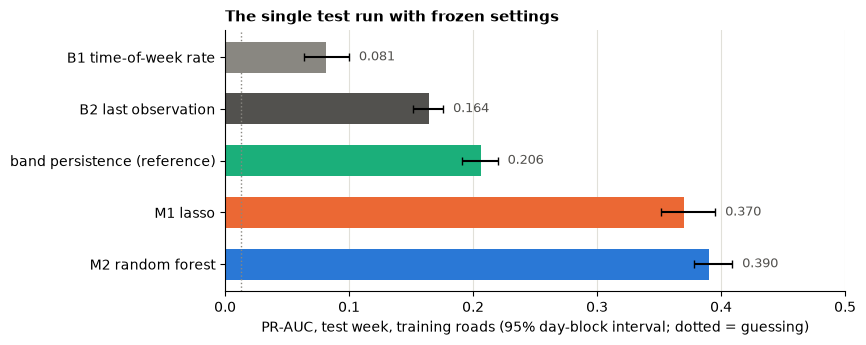

In [16]:
T = json.loads((S.TABLES / "10_test.json").read_text())
rows_t = []
for n in ("B1", "B2", "B2p", "Lasso", "RF"):
    r = T[f"main|{n}"]
    p2, r2 = r["at_share"]["0.02"]
    rows_t.append([LABEL[n], f"{r['pr_auc']:.3f} ({r['ci'][0]:.3f}-{r['ci'][1]:.3f})",
                   "" if n == "B2" else "{:+.3f} ({:+.3f} to {:+.3f})".format(r["minus_B2"], *r["minus_B2_ci"]),
                   f"{p2:.3f} / {r2:.3f}", f"{r['event']['warned']:.1%}",
                   f"{T[f'transfer|{n}']['pr_auc']:.3f} ({T[f'transfer|{n}']['ci'][0]:.3f}-{T[f'transfer|{n}']['ci'][1]:.3f})"])
r = T["main|RF"]
print(f"training roads: {r['rows']:,} rows, {r['onsets']:,} onsets, onset rate {r['base_rate']:.4f}; "
      f"AYE + CTE: {T['transfer|RF']['rows']:,} rows, onset rate {T['transfer|RF']['base_rate']:.4f}")
mdtable(rows_t, ["score", "PR-AUC, training roads (95%)", "minus B2 (paired 95%)", "precision / recall at 2%",
                 "episodes warned 10-15 min ahead", "PR-AUC, AYE + CTE (95%)"])
print("M2 minus M1: {:+.3f} (paired 95% {:+.3f} to {:+.3f})".format(r["minus_Lasso"], *r["minus_Lasso_ci"]))
mdtable([[f"{h} min" + (" (main)" if h == 15 else ""), f"{T[f'horizon{h}']['base_rate']:.4f}"]
         + [f"{T[f'horizon{h}'][n]:.3f}" for n in ("B1", "B2", "Lasso", "RF")] for h in (5, 10, 15, 30)],
        ["horizon", "onset rate", "B1", "B2", "M1 lasso", "M2 forest"])
mdtable([[lab, f"{T[f'ablation|{k}|lasso']['main']:.3f}", f"{T[f'ablation|{k}|rf']['main']:.3f}",
          f"{T[f'ablation|{k}|lasso']['transfer']:.3f}", f"{T[f'ablation|{k}|rf']['transfer']:.3f}"]
         for k, lab in (("no_conn", "without joining roads"), ("no_neighbours", "without neighbour inputs (next links and HOP)"),
                        ("no_hist", "without HIST"), ("base53_trainnorm", "the 53 build inputs only"))],
        ["inputs (frozen settings, refitted)", "lasso, training roads", "forest, training roads", "lasso, AYE + CTE",
         "forest, AYE + CTE"])
fig, ax = plt.subplots(figsize=(8, 3.4))
names = ["B1", "B2", "B2p", "Lasso", "RF"]
vals = [T[f"main|{n}"]["pr_auc"] for n in names]
err = np.array([[T[f"main|{n}"]["pr_auc"] - T[f"main|{n}"]["ci"][0], T[f"main|{n}"]["ci"][1] - T[f"main|{n}"]["pr_auc"]] for n in names]).T
ax.barh(range(5)[::-1], vals, xerr=err[:, :], color=[COLOR[n] for n in names], height=0.6, capsize=3)
ax.set_yticks(range(5)[::-1])
ax.set_yticklabels([LABEL[n] for n in names])
ax.axvline(T["main|RF"]["base_rate"], color=MUTED, linestyle=":", linewidth=1)
for i, n in zip(range(5)[::-1], names):
    ax.text(T[f"main|{n}"]["ci"][1] + 0.008, i, f"{T[f'main|{n}']['pr_auc']:.3f}", va="center", fontsize=9, color=INK2)
ax.set_xlabel("PR-AUC, test week, training roads (95% day-block interval; dotted = guessing)")
ax.set_xlim(0, 0.5)
ax.set_title("The single test run with frozen settings")
ax.grid(axis="y", visible=False)
save(fig, "part3_test_week.png")

In [17]:
pl.DataFrame({"LinkID": main["LinkID"], "t": main["t"], "y": main["y"], "group": main["group"],
              "b1": main["b1"], "b2": main["b2"], "lasso": main["lasso"], "rf_raw": main["rf_raw"],
              "rf_calibrated": platt_apply(main["rf_raw"].to_numpy(), calib["RF"])}
             ).write_parquet(S.PREDS / "part3_validation_scores.parquet")
(S.TABLES / "part3_notebook.json").write_text(json.dumps({
    "b1_m": m_b1, "b1_cv": {str(k_): v_ for k_, v_ in cv_b1.items()}, "b2_cv": b2_cv,
    "screen": {f"{fam}|{'+'.join(('BASE',) + sub)}": aps for (fam, sub), aps in screen.items()},
    "chosen": chosen, "lasso_frac": frac, "lasso_cv": mean_lr, "rf_params": params,
    "rf_cv": {f"{k_[0]}|{k_[1]}": v_ for k_, v_ in grid.items()}, "importance": imp,
    "validation_pr_auc": ap_main, "final": final, "share": share, "calibration": calib}, indent=1, default=str))
log("written the validation scores (work folder) and results/tables/part3_notebook.json")

[ 3496 s] written the validation scores (work folder) and results/tables/part3_notebook.json


## 12. Summary

- **Both models beat both baselines clearly.** On the untouched test week the random forest reaches a PR-AUC of
  **0.390** (95% day-block interval 0.378-0.409) and the lasso 0.370, against 0.164 for last observation and 0.081 for
  the time-of-week rate. The forest's lead over the lasso is small (+0.020) but its paired interval excludes 0.
- **The models transfer** to two roads never used for fitting (AYE + CTE: forest 0.367, lasso 0.326 vs 0.162).
- **In practice**, alerting on the top 2% of links at each update, about 1 alert in 4 is right and 38% of onsets are
  caught 15 minutes ahead; 31.5% of the episodes are warned 10-15 minutes before they start.
- **What drives it**: the normal level ahead (a usual peak that does not end on this link) and queues within about
  1.5 km downstream. Without the neighbour inputs both models lose about 0.07-0.08 PR-AUC; the joining roads add nothing.
- **Limits.** The models predict where a slowdown spreads or deepens; slowdowns that start on a normal-looking road are
  caught only a few percent of the time. The data are one season of school-term weekdays with 16 training days, speed
  bands are 10 km/h wide, a third of the episodes are 10-minute dips, and the intervals rest on 5 test days. Links
  normally at band 1-2 cannot show the 2-band drop the label needs.